# Q2. Are declines concentrated in particular regions, habitats or ecological groups?

Compares change from 1977–1990 to 2006–2020 across zones and map cells, then across trait groups.

In [1]:
from pathlib import Path
import textwrap, warnings, logging
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects
from matplotlib.patches import Rectangle, Patch
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import kruskal
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# ---------------- CUSTOMISE HERE ----------------
DATA_PATH = next(p for p in [Path("combined_atlas_des.parquet"), Path("../combined_atlas_des.parquet")] if p.exists())
TRAITS_PATH = Path("species_traits_provisional.csv")   # diet, habitat, nest, movement, size (provisional, editable)
OUTPUT_DIR = Path("outputs")
PDF_NAME = "Q2_Decline_Concentration.pdf"

# Three Atlas windows: a species "continues to decline" if it fell from the 1st to the 2nd AND from the 2nd to the 3rd
WINDOWS = {"A": (1977, 1990), "B": (1991, 2005), "C": (2006, 2020)}
LIST_BAND = (15, 45)            # only survey lists with this many species, so list length is the same in every window
SHEETS_PER_SQUARE = 4           # survey sheets drawn per grid square in EACH window
REPEATS = 25                    # random draws averaged together
BOOTSTRAP = 400                 # resamples of grid squares for the uncertainty ranges
MIN_OCCUPANCY = 8               # % of squares a species must reach in one window to be assessed

# Q2A - map
CELL_DEG = 1.0                  # map cell size in degrees (about 100 km)
MIN_CELL_SQUARES = 4            # grid squares a map cell needs

ZONES = {"NC": "Coast", "CSC": "Coast", "TS": "Coast", "T": "Tablelands", "NTE": "Tablelands",
         "WS": "Inland", "CP": "Inland", "RP": "Inland", "A": "Inland", "MAW": "Inland"}
ZONE_ORDER = ["Coast", "Tablelands", "Inland"]
INTRODUCED = [957, 989, 991, 995, 996, 998, 999]
SPLIT_NAMES = [291, 294]        # Mallee/Australian Ringneck: a naming change, not a real change
# ------------------------------------------------

OUTPUT_DIR.mkdir(exist_ok=True)
WLAB = {k: f"{a}–{b}" for k, (a, b) in WINDOWS.items()}
print("Data file:", DATA_PATH.resolve())

Data file: /home/user/birdbreed/combined_atlas_des.parquet


In [2]:
# ---- Chart style (same colour-blind-safe palette as the first client report) ----
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8c8b86", "#e6e5e1", "#ffffff"
BLUE, ORANGE, RED, GREY_PT = "#2a78d6", "#eb6834", "#e34948", "#bdbcb6"
DARK_BLUE, LIGHT_BLUE, LIGHT_RED = "#184f95", "#86b6ef", "#f4a7a6"

mpl.rcParams.update({
    "font.family": ["Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9.5, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "pdf.fonttype": 42, "legend.frameon": False,
})
CHART_SIZE = (8.27, 5.4)        # same shape as the chart area on a PDF page
HALO = [mpl.patheffects.withStroke(linewidth=2.4, foreground="white")]

def headline(fig, title, subtitle):
    fig.text(0.07, 0.975, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.07, 0.915, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)

def show(chart, name):
    fig = plt.figure(figsize=CHART_SIZE)
    chart(fig)
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200)
    plt.show()

def tidy_name(n):
    return n.title() if isinstance(n, str) and n.isupper() else n

def answer(Q):
    display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q["findings"]) +
                     f"\n\n**What it means:** {Q['meaning']}\n\n*Caution: {Q['caveat']}*"))

TOWNS = {"Sydney": (-33.87, 151.21), "Newcastle": (-32.93, 151.78), "Canberra": (-35.28, 149.13),
         "Dubbo": (-32.25, 148.60), "Broken Hill": (-31.95, 141.47), "Wagga Wagga": (-35.12, 147.37),
         "Armidale": (-30.51, 151.67), "Bourke": (-30.09, 145.94), "Griffith": (-34.29, 146.04),
         "Port Macquarie": (-31.43, 152.91), "Lismore": (-28.81, 153.28), "Albury": (-36.08, 146.92),
         "Bathurst": (-33.42, 149.58), "Tamworth": (-31.09, 150.93), "Moree": (-29.47, 149.84),
         "Wollongong": (-34.42, 150.89), "Nowra": (-34.88, 150.60), "Bega": (-36.67, 149.84),
         "Cooma": (-36.24, 149.12), "Goulburn": (-34.75, 149.72), "Orange": (-33.28, 149.10),
         "Mudgee": (-32.60, 149.59), "Coonabarabran": (-31.27, 149.28), "Narrabri": (-30.33, 149.78),
         "Grafton": (-29.69, 152.93), "Coffs Harbour": (-30.30, 153.11), "Taree": (-31.90, 152.46),
         "Forbes": (-33.38, 148.01), "Parkes": (-33.14, 148.17), "Cobar": (-31.50, 145.84),
         "Hay": (-34.51, 144.84), "Deniliquin": (-35.53, 144.96), "Narrandera": (-34.75, 146.55),
         "Young": (-34.31, 148.30), "Queanbeyan": (-35.35, 149.23), "Katoomba": (-33.71, 150.31),
         "Gosford": (-33.43, 151.34), "Maitland": (-32.73, 151.56), "Singleton": (-32.57, 151.17),
         "Muswellbrook": (-32.26, 150.89), "Glen Innes": (-29.74, 151.74), "Tenterfield": (-29.05, 152.02),
         "Inverell": (-29.77, 151.11), "Gunnedah": (-30.98, 150.25), "Walgett": (-30.02, 148.12),
         "Wilcannia": (-31.56, 143.38), "Ivanhoe": (-32.90, 144.30), "Balranald": (-34.64, 143.56),
         "Wentworth": (-34.11, 141.92), "Tibooburra": (-29.43, 142.01), "Nyngan": (-31.56, 147.19),
         "Lithgow": (-33.48, 150.16), "Batemans Bay": (-35.71, 150.18), "Eden": (-37.07, 149.90),
         "Tumut": (-35.30, 148.22), "Kempsey": (-31.08, 152.83), "Ballina": (-28.87, 153.56),
         "Leeton": (-34.55, 146.40), "Condobolin": (-33.09, 147.15), "West Wyalong": (-33.92, 147.21),
         "Warren": (-31.70, 147.83), "Coonamble": (-30.95, 148.39), "Brewarrina": (-29.96, 146.86),
         "Menindee": (-32.39, 142.42), "Jindabyne": (-36.42, 148.62), "Scone": (-32.05, 150.87)}

def nearest_town(lat, lon):
    k = min(TOWNS, key=lambda t: (TOWNS[t][0] - lat) ** 2 + ((TOWNS[t][1] - lon) * np.cos(np.radians(lat))) ** 2)
    dist = 111 * np.hypot(TOWNS[k][0] - lat, (TOWNS[k][1] - lon) * np.cos(np.radians(lat)))
    return k if dist < 15 else f"near {k}"

def nsw_axes(ax):
    ax.set_aspect(1 / np.cos(np.radians(33)))
    ax.set_xlim(140.8, 154); ax.set_ylim(-37.7, -28.0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)

def label_towns(ax, towns, size=7.2):
    for t in towns:
        la, lo = TOWNS[t]
        ax.plot(lo, la, "o", ms=2.8, color=INK, zorder=5)
        ax.text(lo + 0.12, la + 0.08, t, fontsize=size, color=INK, zorder=5, path_effects=HALO)


DIV = {"much_less": "#d43d3c", "less": "#f4a7a6", "typical": "#e6e5e1", "more": "#86b6ef", "much_more": "#256abf"}

## Data
Atlas surveys, 1977–2020, in three periods. To compare fairly, each period uses the same grid squares, the same
number of single-month survey lists per square (4), and lists of similar length (15–45 species). Each species is
measured as the share of squares where it was recorded, relative to the typical species.

In [3]:
cols = ["source", "sheet_id", "species_id", "common_name", "breeding", "is_collection", "year", "single_month",
        "klat", "klon", "region", "usable"]
raw = pd.read_parquet(DATA_PATH, columns=cols)
for c in ["source", "sheet_id", "common_name", "region"]:
    raw[c] = raw[c].astype("category")
data = raw[raw["usable"]].copy()
del raw
data["lat"] = -(data["klat"] // 100 + (data["klat"] % 100) / 60)    # grid codes are square centres
data["lon"] = data["klon"] // 100 + (data["klon"] % 100) / 60
data = data[data["lat"].between(-37.7, -28.0) & data["lon"].between(140.9, 153.7)]
data["square"] = data["klat"].astype(int) * 100000 + data["klon"].astype(int)
names = data.drop_duplicates("species_id").set_index("species_id")["common_name"].astype(str).map(tidy_name)

atlas = data[(data["source"] == "Atlas") & ~data["is_collection"]
             & data["year"].between(WINDOWS["A"][0], WINDOWS["C"][1])].copy()
atlas["list_len"] = atlas["sheet_id"].map(atlas.groupby("sheet_id", observed=True).size()).astype(int)
atlas = atlas[atlas["list_len"].between(*LIST_BAND) & atlas["single_month"].astype(bool)]
edges = [WINDOWS["A"][0] - 1] + [WINDOWS[k][1] for k in "ABC"]
atlas["window"] = pd.cut(atlas["year"], edges, labels=list("ABC")).astype(str)

sheets = atlas.drop_duplicates("sheet_id")[["sheet_id", "square", "window", "list_len", "region"]]
per_sq = sheets.groupby(["square", "window"]).size().unstack(fill_value=0)
SQUARES = per_sq[(per_sq[list("ABC")] >= SHEETS_PER_SQUARE).all(axis=1)].index
sheets = sheets[sheets["square"].isin(SQUARES)]
rows = atlas[atlas["sheet_id"].isin(sheets["sheet_id"])][["sheet_id", "species_id", "square", "window", "breeding"]]

det, mean_len = None, []
for rep in range(REPEATS):
    pick = sheets.sample(frac=1, random_state=rep)
    pick = pick[pick.groupby(["square", "window"]).cumcount() < SHEETS_PER_SQUARE]
    mean_len.append(pick.groupby("window")["list_len"].mean())
    x = rows[rows["sheet_id"].isin(pick["sheet_id"])]
    p = x.groupby(["species_id", "square", "window"]).size().gt(0).astype(float)
    det = p if det is None else det.add(p, fill_value=0)
# Probability that each species is recorded in each square and window (averaged over the draws)
det = (det / REPEATS).unstack("window", fill_value=0).reindex(columns=list("ABC"), fill_value=0)

sq_info = atlas.drop_duplicates("square").set_index("square").loc[SQUARES, ["lat", "lon", "region"]]
sq_info["zone"] = sq_info["region"].astype(str).map(ZONES)
display(pd.DataFrame({"years": pd.Series(WLAB), "average species per list": pd.concat(mean_len, axis=1).mean(axis=1).round(1),
                      "sheets available": sheets.groupby("window").size()}))
print(f"{len(SQUARES)} grid squares surveyed in all three windows "
      f"({sq_info['zone'].value_counts().reindex(ZONE_ORDER).to_dict()})")

,years,average species per list,sheets available
A,1977–1990,28.4,10709
B,1991–2005,26.8,30188
C,2006–2020,28.6,9524


432 grid squares surveyed in all three windows ({'Coast': 117, 'Tablelands': 135, 'Inland': 179})


## Species trends
Same classification as the Q1 notebook, repeated so this notebook runs on its own.

In [4]:
occ = det.groupby("species_id").sum() / len(SQUARES) * 100
occ = occ[occ.max(axis=1) >= MIN_OCCUPANCY].drop(SPLIT_NAMES, errors="ignore")
STEPS = {"AB": ("A", "B"), "BC": ("B", "C"), "AC": ("A", "C")}
TYPICAL = {k: (occ[b] / occ[a]).median() for k, (a, b) in STEPS.items()}
q1 = occ.copy()
q1["name"] = names.reindex(q1.index)
for k, (a, b) in STEPS.items():
    q1[k] = q1[b] / q1[a] / TYPICAL[k]          # 1 = changed like the typical species

# Uncertainty: resample grid squares
M = {w: det[w].unstack("square", fill_value=0).reindex(index=q1.index, columns=SQUARES, fill_value=0).values
     for w in "ABC"}
rng = np.random.default_rng(0)
boot = {k: [] for k in STEPS}
for _ in range(BOOTSTRAP):
    idx = rng.integers(0, len(SQUARES), len(SQUARES))
    o = {w: M[w][:, idx].mean(axis=1) for w in "ABC"}
    for k, (a, b) in STEPS.items():
        r = o[b] / o[a]
        boot[k].append(r / np.nanmedian(r))
for k in STEPS:
    arr = np.array(boot[k])
    q1[k + "_lo"], q1[k + "_hi"] = np.nanpercentile(arr, 2.5, axis=0), np.nanpercentile(arr, 97.5, axis=0)

down_recent = q1["BC_hi"] < 1
continuing = down_recent & (q1["AB"] < 1) & (q1["AC_hi"] < 1)
q1["trend"] = np.select(
    [continuing, down_recent, q1["AB_hi"] < 1, q1["AC_lo"] > 1],
    ["Continuing decline", "New decline", "Declined earlier, now steady", "Increasing"], "No clear change")
q1["introduced"] = q1.index.isin(INTRODUCED)

# Breeding check: of the sightings of each species, the share with breeding evidence (as in the first report),
# 1977-1990 vs 2006-2020, relative to the typical species (breeding was recorded less often overall)
MIN_BREEDING = 20
bs = atlas.groupby(["species_id", "window"])["breeding"].agg(["size", "sum"]).unstack(fill_value=0)
share = bs["sum"] / bs["size"]
breed_rel = share["C"] / share["A"]
breed_typ = breed_rel[bs["sum"]["A"] >= MIN_BREEDING].median()
q1["breed_records_A"] = bs["sum"]["A"].reindex(q1.index).fillna(0)
q1["breed_AC"] = (breed_rel / breed_typ).reindex(q1.index)
traits = pd.read_csv(TRAITS_PATH).set_index("species_id")

native = q1[~q1["introduced"]]
cont = native[native["trend"] == "Continuing decline"].sort_values("AC")
cont_intro = q1[(q1["trend"] == "Continuing decline") & q1["introduced"]]
counts = native["trend"].value_counts()
cont_breed = cont[cont["breed_records_A"] >= MIN_BREEDING]
cont_ins = cont.index.isin(traits.index[traits["diet"] == "Insects"]).sum()
n_breed_down = (cont_breed["breed_AC"] < 1).sum()
display(counts.to_frame("native species"))
print("Typical species change:", {k: f"{v - 1:+.0%}" for k, v in TYPICAL.items()})
display(cont[["name", "A", "B", "C", "AB", "BC", "AC", "breed_AC"]].round(2))

,native species
trend,
Increasing,60
No clear change,42
"Declined earlier, now steady",33
Continuing decline,27
New decline,23


Typical species change: {'AB': '-4%', 'BC': '+0%', 'AC': '-4%'}


window,name,A,B,C,AB,BC,AC,breed_AC
species_id,,,,,,,,
385,Hooded Robin,14.06,7.13,3.29,0.53,0.46,0.24,0.44
337,Pallid Cuckoo,16.36,12.27,6.82,0.78,0.55,0.44,1.24
225,Little Eagle,18.11,11.56,8.14,0.66,0.70,0.47,2.69
484,Buff-rumped Thornbill,24.32,17.90,11.40,0.76,0.63,0.49,2.08
380,Scarlet Robin,16.68,10.93,7.81,0.68,0.71,0.49,1.30
260,Little Lorikeet,12.75,9.62,6.01,0.78,0.62,0.49,0.68
547,Dusky Woodswallow,40.32,25.79,20.65,0.66,0.80,0.54,0.86
369,Restless Flycatcher,41.06,30.57,21.45,0.77,0.70,0.55,0.89
416,Crested Shrike-tit,22.55,16.28,12.16,0.75,0.74,0.56,0.89


## Regions

In [5]:
det_sq = det.reset_index().merge(sq_info[["zone", "lat", "lon"]], left_on="square", right_index=True)
det_sq = det_sq[~det_sq["species_id"].isin(SPLIT_NAMES)]

def zone_change(sq_subset, species=None):
    # sq_subset may repeat squares (bootstrap), so weight each square by how often it was drawn
    w = pd.Series(sq_subset).value_counts()
    d = det_sq[det_sq["square"].isin(w.index)].copy()
    d[["A", "C"]] = d[["A", "C"]].mul(d["square"].map(w), axis=0)
    o = d.groupby("species_id")[["A", "C"]].sum() / len(sq_subset) * 100
    o = o[o.max(axis=1) >= 10] if species is None else o.reindex(species).fillna(0)
    return o["C"] / o["A"]

zone_rows, zone_ratio = [], {}
rng = np.random.default_rng(1)
for z in ZONE_ORDER:
    sqs = sq_info.index[sq_info["zone"] == z].values
    r = zone_ratio[z] = zone_change(sqs)
    bs = [zone_change(rng.choice(sqs, len(sqs)), r.index).median() for _ in range(200)]
    zone_rows.append(dict(zone=z, squares=len(sqs), species=len(r), median=r.median(),
                          lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5), down30=(r <= 0.7).mean() * 100,
                          up30=(r >= 1 / 0.7).mean() * 100))
zones = pd.DataFrame(zone_rows).set_index("zone")
zones.round(3).to_csv(OUTPUT_DIR / "Q2_regions_zone_summary.csv")

# Where does each continuing decliner fall hardest?
cz = pd.DataFrame({z: zone_ratio[z].reindex(cont.index) for z in ZONE_ORDER})
cz["worst"] = cz.idxmin(axis=1)
worst_zone = cz["worst"].value_counts().reindex(ZONE_ORDER, fill_value=0)
cz.insert(0, "name", cont["name"])
cz.round(2).to_csv(OUTPUT_DIR / "Q2_regions_continuing_decliners_by_zone.csv")

# Map cells
sq_info["cell_lat"] = np.floor(sq_info["lat"] / CELL_DEG) * CELL_DEG
sq_info["cell_lon"] = np.floor(sq_info["lon"] / CELL_DEG) * CELL_DEG
cell_rows = []
for (cla, clo), g in sq_info.groupby(["cell_lat", "cell_lon"]):
    if len(g) < MIN_CELL_SQUARES:
        continue
    d = det_sq[det_sq["square"].isin(g.index)]
    present = d.groupby("species_id")[["A", "C"]].apply(lambda v: ((v > 0).sum() >= 2).any())
    o = d[d["species_id"].isin(present[present].index)].groupby("species_id")[["A", "C"]].sum()
    o = o[(o["A"] > 0)]
    cell_rows.append(dict(cell_lat=cla, cell_lon=clo, squares=len(g), species=len(o),
                          change=(o["C"] / o["A"]).median()))
cells = pd.DataFrame(cell_rows)
BINS = [0, 0.75, 0.9, 1 / 0.9, 1 / 0.75, np.inf]
CLASS = ["much_less", "less", "typical", "more", "much_more"]
CLASS_LABEL = ["Down 25% or more", "Down 10–25%", "Within 10%", "Up 10–33%", "Up 33% or more"]
cells["cls"] = pd.cut(cells["change"], BINS, labels=CLASS, right=False)
cells.round(3).to_csv(OUTPUT_DIR / "Q2_regions_map_cells.csv", index=False)
display(zones.round(2)); display(worst_zone.to_frame("continuing decliners falling hardest here"))
print(f"{len(cells)} map cells; {cells['cls'].isin(['much_less', 'less']).mean():.0%} down 10% or more")

,squares,species,median,lo,hi,down30,up30
zone,,,,,,,
Coast,117,172,0.88,0.87,0.94,25.00,13.37
Tablelands,135,164,0.90,0.86,0.94,28.05,17.07
Inland,179,156,0.99,0.97,1.02,21.15,12.82


,continuing decliners falling hardest here
worst,
Coast,11
Tablelands,7
Inland,9


41 map cells; 41% down 10% or more


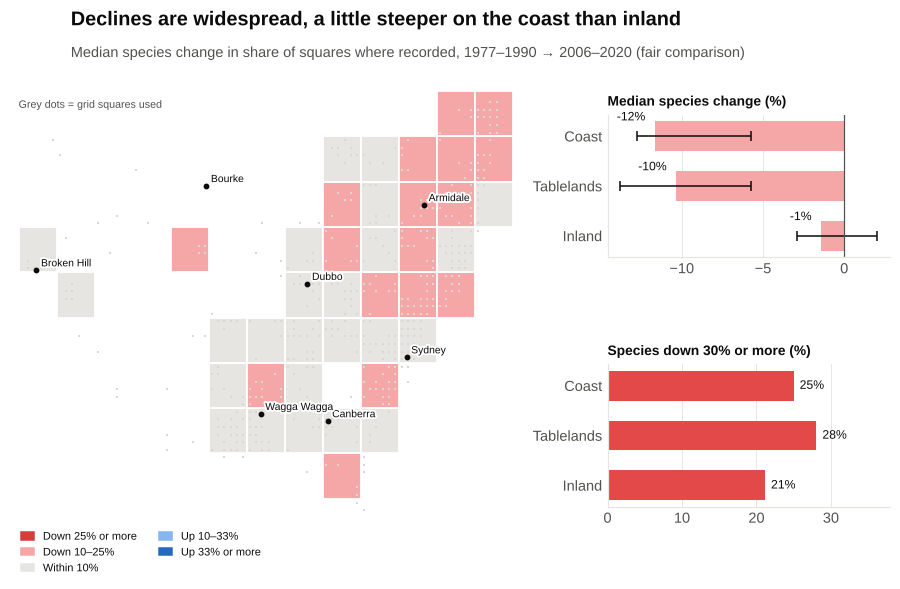

In [6]:
def chart_q2a(fig):
    worst = zones["median"].idxmin()
    headline(fig, f"Declines are widespread, a little steeper on the {worst.lower()} than inland",
             f"Median species change in share of squares where recorded, {WLAB['A']} → {WLAB['C']} (fair comparison)")
    mx = fig.add_axes([0.0, 0.10, 0.56, 0.74])
    mx.scatter(sq_info["lon"], sq_info["lat"], s=2.5, marker="s", color="#d9d8d3", lw=0, zorder=2)
    for _, r in cells.iterrows():
        mx.add_patch(Rectangle((r["cell_lon"], r["cell_lat"]), CELL_DEG, CELL_DEG, facecolor=DIV[r["cls"]],
                               edgecolor="white", lw=1.2, zorder=1))
    nsw_axes(mx)
    label_towns(mx, ["Sydney", "Canberra", "Dubbo", "Armidale", "Wagga Wagga", "Broken Hill", "Bourke"], size=6.8)
    handles = [Patch(color=DIV[c], label=l) for c, l in zip(CLASS, CLASS_LABEL)]
    mx.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 0.02), ncol=2, fontsize=7.2, handlelength=1.2)
    mx.text(141.0, -28.2, "Grey dots = grid squares used", fontsize=7, color=INK2, va="top")
    bx = fig.add_gridspec(2, 1, left=0.66, right=0.97, top=0.80, bottom=0.14, hspace=0.75).subplots()
    y = np.arange(len(ZONE_ORDER))[::-1]
    v = (zones["median"] - 1) * 100
    bx[0].barh(y, v, color=[DIV["less"] if x < 0 else DIV["more"] for x in v], height=0.6)
    bx[0].errorbar(v, y, xerr=[np.clip(v - (zones["lo"] - 1) * 100, 0, None),
                                     np.clip((zones["hi"] - 1) * 100 - v, 0, None)], fmt="none", ecolor=INK,
                   elinewidth=1, capsize=3)
    bx[0].set_yticks(y, ZONE_ORDER); bx[0].axvline(0, color=INK2, lw=0.8)
    bx[0].set_title("Median species change (%)", loc="left", fontsize=9, fontweight="bold")
    bx[0].grid(axis="y", visible=False)
    for yi, val in zip(y, v):
        bx[0].text(val - 0.6 if val < 0 else val + 0.6, yi + 0.38, f"{val:+.0f}%", fontsize=8, va="center",
                   ha="right" if val < 0 else "left")
    bx[1].barh(y, zones["down30"], color=RED, height=0.6)
    bx[1].set_yticks(y, ZONE_ORDER); bx[1].grid(axis="y", visible=False)
    bx[1].set_title("Species down 30% or more (%)", loc="left", fontsize=9, fontweight="bold")
    for yi, val in zip(y, zones["down30"]):
        bx[1].text(val + 0.8, yi, f"{val:.0f}%", fontsize=8, va="center")
    bx[1].set_xlim(0, zones["down30"].max() * 1.35)

show(chart_q2a, "Q2_regions")

In [7]:

order = zones["median"].sort_values().index.tolist()
def where(z): return "inland" if z == "Inland" else z.lower()
Q2A_POINTS = [
    "Typical species change: " + ", ".join(f"{where(z)} {(zones.loc[z, 'median'] - 1) * 100:+.0f}%" for z in ZONE_ORDER) + ".",
    f"{cells['cls'].isin(['much_less', 'less']).mean():.0%} of map cells are down 10% or more, scattered across the "
    f"state rather than clustered.",
    "Continuing decliners fall hardest: " + ", ".join(f"{where(z)} {n}" for z, n in
                                                     worst_zone.sort_values(ascending=False).items()) + " species.",
]
display(Markdown("\n".join(f"* {p}" for p in Q2A_POINTS)))


* Typical species change: coast -12%, tablelands -10%, inland -1%.
* 41% of map cells are down 10% or more, scattered across the state rather than clustered.
* Continuing decliners fall hardest: coast 11, inland 9, tablelands 7 species.

## Habitats and ecological groups
Traits come from `species_traits_provisional.csv` (provisional).

In [8]:
traits = pd.read_csv(TRAITS_PATH).set_index("species_id")
TRAITS = [("habitat", "Main habitat"), ("diet", "Main diet"), ("nest", "Nest type"), ("movement", "Movement"),
          ("size", "Body size")]
q2b = native.join(traits[[t for t, _ in TRAITS]], how="inner")
q2b["pct"] = (q2b["AC"] - 1) * 100
q2b["cont"] = q2b["trend"] == "Continuing decline"
rng = np.random.default_rng(2)
grp_rows, tests = [], {}
for t, label in TRAITS:
    groups = {g: v for g, v in q2b.groupby(t) if len(v) >= 5}
    tests[label] = kruskal(*[v["pct"] for v in groups.values()]).pvalue
    for g, v in groups.items():
        bs = [np.median(rng.choice(v["pct"].values, len(v))) for _ in range(2000)]
        grp_rows.append(dict(trait=label, group=g, n=len(v), median=v["pct"].median(), lo=np.percentile(bs, 2.5),
                             hi=np.percentile(bs, 97.5), n_cont=int(v["cont"].sum()), share_cont=v["cont"].mean() * 100))
grp = pd.DataFrame(grp_rows)
# Holm adjustment across the five traits
p = pd.Series(tests).sort_values()
holm = pd.Series(np.minimum(1, np.maximum.accumulate(p.values * (len(p) - np.arange(len(p))))), index=p.index)
grp["trait_p"] = grp["trait"].map(holm)
grp.round(3).to_csv(OUTPUT_DIR / "Q2_groups.csv", index=False)
missing = native.index.difference(traits.index)
display(holm.round(4).to_frame("Holm-adjusted p (do groups differ?)"))
display(grp.sort_values("median").round(1).head(8))
print(f"{len(q2b)} native species with traits; {len(missing)} without traits: {list(names.reindex(missing))}")

,Holm-adjusted p (do groups differ?)
Body size,0.0000
Main diet,0.0000
Nest type,0.0211
Movement,0.0271
Main habitat,0.0605


,trait,group,n,median,lo,hi,n_cont,share_cont,trait_p
25,Body size,Small (under 50 g),81,-17.8,-26.2,-13.2,22,27.2,0.0
15,Nest type,Dome,24,-17.1,-26.2,-6.5,5,20.8,0.0
9,Main diet,Insects,78,-16.4,-23.7,-9.1,18,23.1,0.0
14,Nest type,Brood parasite,6,-16.1,-49.9,131.6,2,33.3,0.0
22,Movement,Summer migrant,28,-15.5,-22.5,-9.5,6,21.4,0.0
6,Main habitat,Woodland,65,-15.3,-25.4,-2.0,21,32.3,0.1
1,Main habitat,Forest,39,-6.2,-13.2,9.5,5,12.8,0.1
16,Nest type,Ground or burrow,22,-3.5,-18.0,10.4,1,4.5,0.0


185 native species with traits; 0 without traits: []


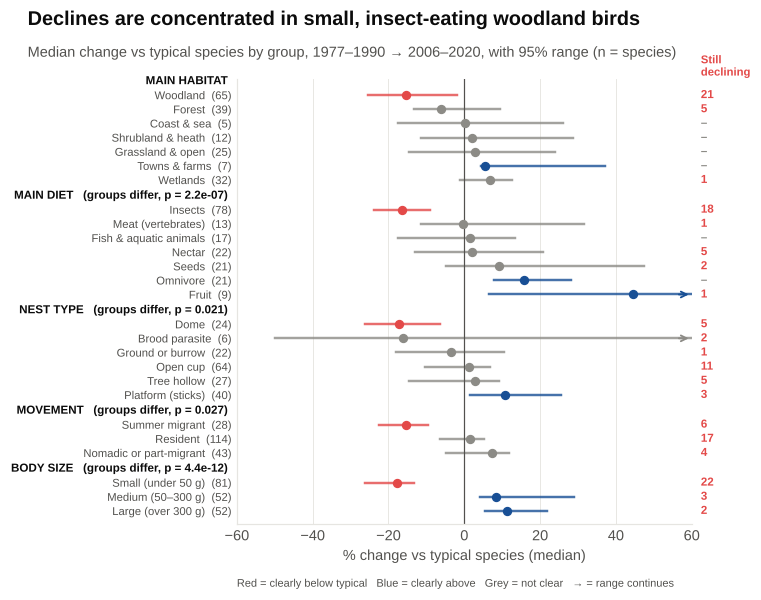

In [9]:
def chart_q2b(fig):
    lows = grp[grp["hi"] < 0].sort_values("median")
    headline(fig, "Declines are concentrated in small, insect-eating woodland birds",
             f"Median change vs typical species by group, {WLAB['A']} → {WLAB['C']}, with 95% range (n = species)")
    ax = fig.add_gridspec(1, 1, left=0.30, right=0.80, top=0.86, bottom=0.11).subplots()
    LIM = 60                      # wider ranges (very small groups) are cut off with an arrow
    y, ticks, labels, ycur = [], [], [], 0
    for t, label in TRAITS:
        g = grp[grp["trait"] == label].sort_values("median")
        ax.text(-0.02, ycur - 0.15, f"{label.upper()}" + (f"   (groups differ, p = {holm[label]:.2g})"
                if holm[label] < 0.05 else ""), transform=ax.get_yaxis_transform(), ha="right", fontsize=7.6,
                fontweight="bold", color=INK, va="bottom")
        ycur -= 0.75
        for _, r in g.iterrows():
            col = RED if r["hi"] < 0 else (DARK_BLUE if r["lo"] > 0 else MUTED)
            ax.plot([max(r["lo"], -LIM), min(r["hi"], LIM)], [ycur, ycur], color=col, lw=1.6, alpha=0.8)
            if r["hi"] > LIM:
                ax.annotate("", (LIM, ycur), (LIM * 0.93, ycur), arrowprops=dict(arrowstyle="->", color=col, lw=1.2))
            if r["lo"] < -LIM:
                ax.annotate("", (-LIM, ycur), (-LIM * 0.93, ycur), arrowprops=dict(arrowstyle="->", color=col, lw=1.2))
            ax.scatter(r["median"], ycur, s=26, color=col, zorder=3)
            ticks.append(ycur); labels.append(f"{r['group']}  ({r['n']})")
            ax.text(1.02, ycur, f"{r['n_cont']}" if r["n_cont"] else "–", transform=ax.get_yaxis_transform(),
                    fontsize=7.6, va="center", color=RED if r["n_cont"] else MUTED, fontweight="bold")
            ycur -= 1
        ycur -= 0.35
    ax.set_yticks(ticks, labels, fontsize=7.4)
    ax.set_ylim(ycur + 0.4, 0.4)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_xlim(-LIM, LIM)
    ax.set_xlabel("% change vs typical species (median)")
    ax.grid(axis="y", visible=False)
    ax.text(1.02, 1.0, "Still\ndeclining", transform=ax.transAxes, fontsize=7.4, color=RED, va="bottom",
            fontweight="bold")
    fig.text(0.30, 0.005, "Red = clearly below typical   Blue = clearly above   Grey = not clear   "
             "→ = range continues", fontsize=7.2, color=INK2)

show(chart_q2b, "Q2_groups")

In [10]:

lows = grp[grp["hi"] < 0].sort_values("median")
highs = grp[grp["lo"] > 0].sort_values("median", ascending=False)
SHORT = {"Small (under 50 g)": "small birds", "Large (over 300 g)": "large birds", "Medium (50–300 g)": "medium birds",
         "Insects": "insect-eaters", "Fruit": "fruit-eaters", "Omnivore": "omnivores", "Seeds": "seed-eaters",
         "Nectar": "nectar-eaters", "Dome": "dome nesters", "Platform (sticks)": "stick-nest builders",
         "Summer migrant": "summer migrants", "Woodland": "woodland birds", "Tree hollow": "hollow nesters"}
def fmt(g): return ", ".join(f"{SHORT.get(r['group'], r['group'].lower())} ({r['median']:+.0f}%)" for _, r in g.iterrows())
diff = [k.lower() for k, v in holm.items() if v < 0.05]
Q2B_POINTS = [
    f"Clearly below typical: {fmt(lows)}." if len(lows) else "No group is clearly below typical.",
    f"Clearly above typical: {fmt(highs.head(3))}." if len(highs) else "No group is clearly above typical.",
    f"Groups differ by more than chance for {', '.join(diff)}"
    + ("; habitat differences are suggestive only." if "main habitat" not in diff else ".") if diff else
    "No trait separates the groups by more than chance.",
]
display(Markdown("\n".join(f"* {p}" for p in Q2B_POINTS)))


* Clearly below typical: small birds (-18%), dome nesters (-17%), insect-eaters (-16%), summer migrants (-15%), woodland birds (-15%).
* Clearly above typical: fruit-eaters (+45%), omnivores (+16%), large birds (+11%).
* Groups differ by more than chance for body size, main diet, nest type, movement; habitat differences are suggestive only.

## PDF

In [11]:

logging.getLogger("fontTools").setLevel(logging.ERROR)
A4 = (8.27, 11.69)
M = 0.7                                  # page margin, inches

def _text(fig, y, s, size, weight="normal", color=INK, width=100):
    for line in textwrap.wrap(s, width=width):
        fig.text(M / A4[0], 1 - y / A4[1], line, fontsize=size, fontweight=weight, color=color, va="top")
        y += size * 1.4 / 72
    return y

def plain_page(pdf, title, chart, bullets, note, subtitle=None):
    """White page: question, chart, three short points, one-line note."""
    fig = plt.figure(figsize=A4)
    y = _text(fig, M, title, 15, "bold", width=70)
    if subtitle:
        y = _text(fig, y + 0.05, subtitle, 11, color=INK2)
    top, height = y + 0.25, 5.4
    sub = fig.subfigures(3, 1, height_ratios=[top, height, A4[1] - top - height], hspace=0)[1]
    chart(sub)
    y = top + height + 0.35
    for b in bullets:
        fig.text(M / A4[0], 1 - y / A4[1], "–", fontsize=10.5, va="top")
        y = _text(fig, y, "   " + b, 10.5, width=95) + 0.1
    _text(fig, A4[1] - M - 0.3, note, 8, color=MUTED, width=135)
    pdf.savefig(fig); plt.close(fig)

TITLE = "Are declines concentrated in particular regions, habitats or ecological groups?"
NOTE = (f"Atlas surveys {WLAB['A'][:4]}–{WLAB['C'][-4:]}; same effort per grid square in each period "
        f"({len(SQUARES)} squares). Change is {WLAB['A']} to {WLAB['C']}. ")
with PdfPages(OUTPUT_DIR / PDF_NAME) as pdf:
    plain_page(pdf, TITLE, chart_q2a, Q2A_POINTS, NOTE + "Region names are not yet confirmed, so zones are used.",
               subtitle="Regions")
    plain_page(pdf, TITLE, chart_q2b, Q2B_POINTS, NOTE + "Traits are provisional "
               "(species_traits_provisional.csv) and should be checked against the team's trait table.",
               subtitle="Habitats and ecological groups")
    pdf.infodict()["Title"] = TITLE
print("PDF written to", (OUTPUT_DIR / PDF_NAME).resolve())


PDF written to /home/user/birdbreed/decline_patterns/outputs/Q2_Decline_Concentration.pdf
